# 11 | Full-run sampling with nuisance training refitted

**Question:** How much changes when each FC draw retrains its WM/CSF nuisance model? Compare exactly paired frozen, coefficient-only and complete refits, on fixed and reselected SC support.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## One draw, three estimators
Reuse all saved original-time blocks and all 500 whole-run SC bootstraps from notebook 10. **Frozen** samples the old residuals. **Coefficients** fixes the censor-pool's five anatomical PC scores but refits regression coefficients and scaling. **Full refit** also retrains tissue temporal projection, voxel centering/scaling and five-PC extraction. Spatial masks, image correction, ROI signals, motion and censor eligibility stay fixed.

Multiplicity weights give the same estimator as explicitly repeating sampled rows. Derivatives and DCT time coordinates remain on the original 180-frame axis: artificial block joins do not become motion events. All ROI signals move together. The crossed cells share rows and columns and are dependent; these are conditional computational ranges, not clinical confidence intervals.

,protocol,requested,paired_eligible,minimum_for_summary,summary_available,preop_eligible,preop_unique_min,preop_unique_median,preop_unique_max,postop_eligible,postop_unique_min,postop_unique_median,postop_unique_max
0,primary_block5,200,200,100,True,200,72,93.0,107,200,75,96.0,111
1,primary_block10,200,200,100,True,200,73,93.5,120,200,74,96.0,114
2,primary_block20,200,200,100,True,200,62,96.0,127,200,66,99.0,126
3,strict_block5,200,0,100,False,0,32,44.0,53,129,47,62.0,72
4,strict_block10,200,0,100,False,0,29,44.5,56,126,40,61.0,75
5,strict_block20,200,0,100,False,2,27,45.0,61,135,46,63.0,85


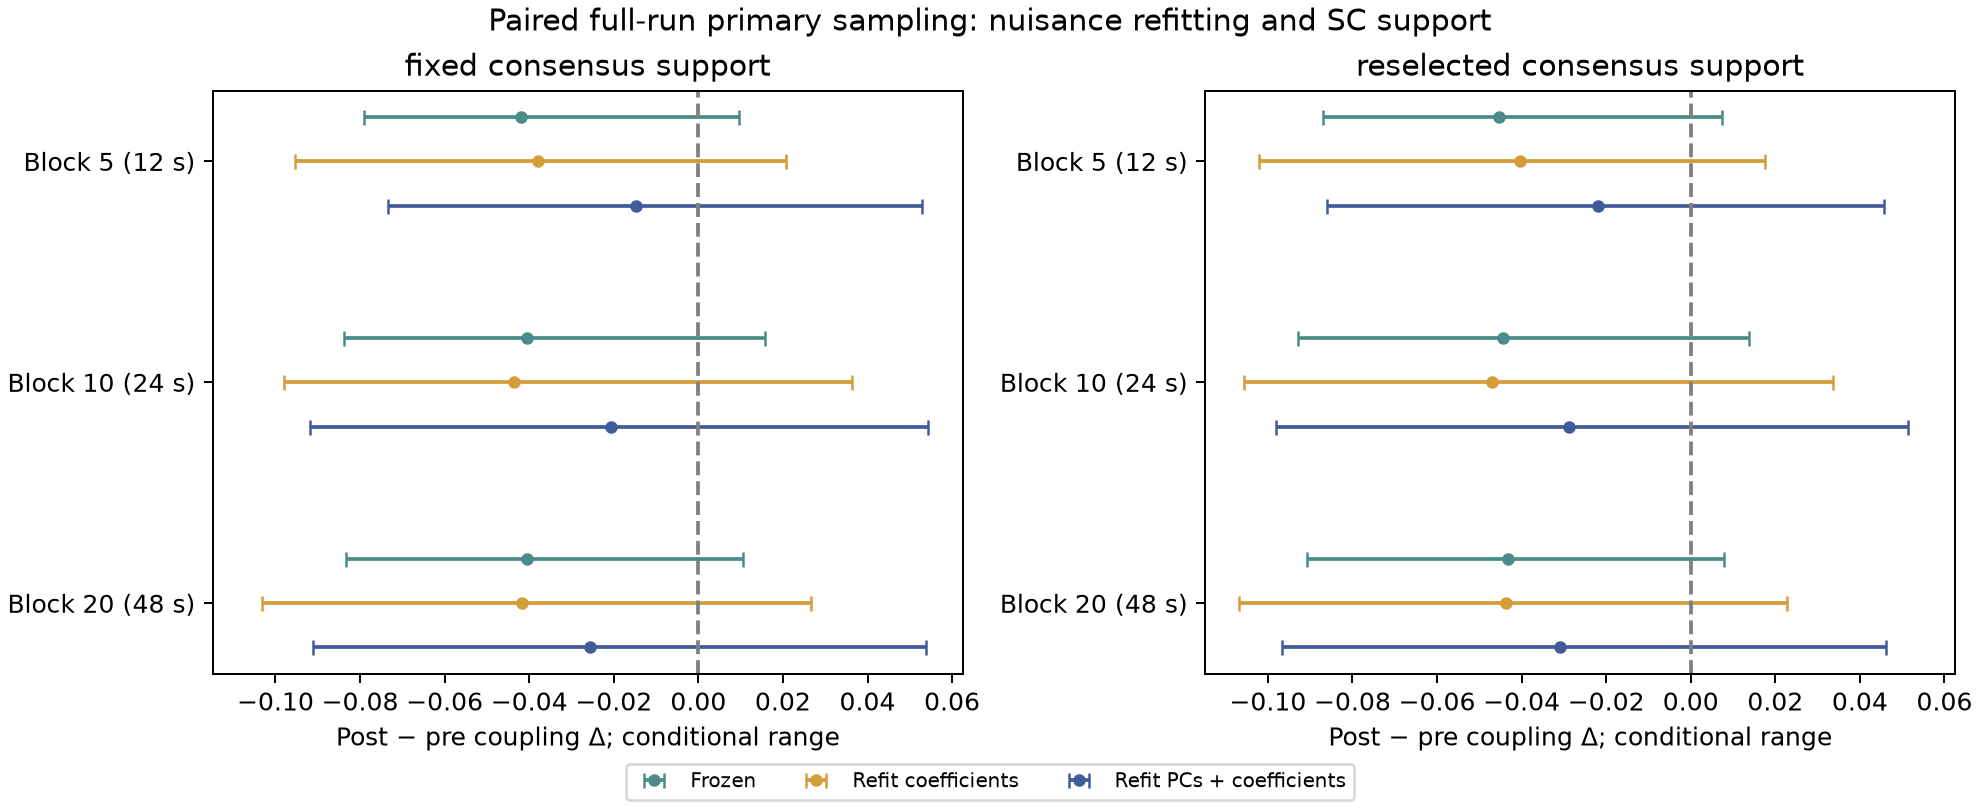

In [2]:
from pat16.joint_refit import OUT as REFIT, PROTOCOLS as RP, MODES as RM
refit_design=json.loads((REFIT/"design.json").read_text())
refit_summary=pd.read_csv(REFIT/"summary.csv")
fit_qc=pd.read_csv(REFIT/"fit_qc.csv")
feasibility=pd.read_csv(REFIT/"feasibility.csv")
display(feasibility)
display(Image(filename=str(RESULTS/"figures/joint_refit_ranges.png")))

## Duplicates are frequency, not new measured information
Every requested draw is attempted. We explicitly impose the conservative feasibility safeguards **≥60 distinct original frames** and **≥15 distinct rows minus design rank**, with agreement between design and solver rank. This extends the existing fit safeguards to distinct bootstrap rows; it is not a universal bootstrap theorem. Neither count-minus-rank estimates independent BOLD information. Save failed-draw QC and NaN FC, never replace failures.

Compare all three models only on the same eligible paired draws. A range requires at least 100 of 200 planned pairs, chosen before computing the contrasts. Always inspect the counts; rejection can change the conditional population. Strict pre-op starts with only 68 retained frames, so block repetitions can leave too few distinct rows for the 39-column model. Withholding its range is a result, not evidence of a stable sign. Notebook 10 retains the original all-draw frozen results, and its six distinct-frame matched designs remain separate fully refitted sensitivities.

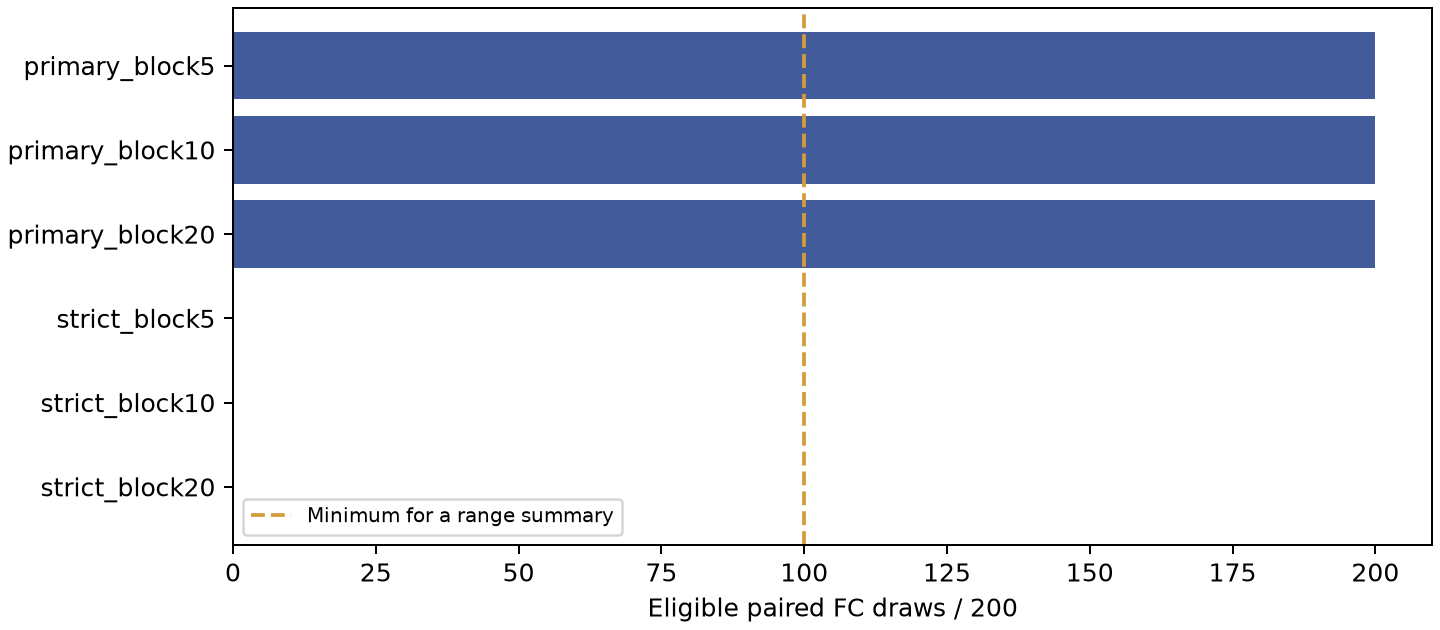

attempted  eligible  unique_min  \
protocol        session mode                                            
primary_block10 postop  coefficients        200       200          74   
                        full_refit          200       200          74   
                preop   coefficients        200       200          73   
                        full_refit          200       200          73   
primary_block20 postop  coefficients        200       200          66   
                        full_refit          200       200          66   
                preop   coefficients        200       200          62   
                        full_refit          200       200          62   
primary_block5  postop  coefficients        200       200          75   
                        full_refit          200       200          75   
                preop   coefficients        200       200          72   
                        full_refit          200       200          72   
strict_block10  postop  coefficients        200       126          40   
                        full_refit          200       126          40   
                preop   coefficients        200         0          29   
                        full_refit          200         0          29   
strict_block20  postop  coefficients        200       135          46   
                        full_refit          200       135          46   
                preop   coefficients        200         2          27   
                        full_refit          200         2          27   
strict_block5   postop  coefficients        200       129          47   
                        full_refit          200       129          47   
                preop   coefficients        200         0          32   
                        full_refit          200         0          32   

                                      unique_median  unique_max  \
protocol        session mode                                      
primary_block10 postop  coefficients           96.0         114   
                        full_refit             96.0         114   
                preop   coefficients           93.5         120   
                        full_refit             93.5         120   
primary_block20 postop  coefficients           99.0         126   
                        full_refit             99.0         126   
                preop   coefficients           96.0         127   
                        full_refit             96.0         127   
primary_block5  postop  coefficients           96.0         111   
                        full_refit             96.0         111   
                preop   coefficients           93.0         107   
                        full_refit             93.0         107   
strict_block10  postop  coefficients           61.0          75   
                        full_refit             61.0          75   
                preop   coefficients           44.5          56   
                        full_refit             44.5          56   
strict_block20  postop  coefficients           63.0          85   
                        full_refit             63.0          85   
                preop   coefficients           45.0          61   
                        full_refit             45.0          61   
strict_block5   postop  coefficients           62.0          72   
                        full_refit             62.0          72   
                preop   coefficients           44.0          53   
                        full_refit             44.0          53   

                                      minimum_distinct_residual  \
protocol        session mode                                      
primary_block10 postop  coefficients                         35   
                        full_refit                           35   
                preop   coefficients                         34   
                        full_refit                           

In [3]:
display(Image(filename=str(RESULTS/"figures/joint_refit_feasibility.png")))
display(fit_qc.groupby(["protocol","session","mode"]).agg(attempted=("draw","count"),eligible=("eligible","sum"),unique_min=("unique_frames","min"),unique_median=("unique_frames","median"),unique_max=("unique_frames","max"),minimum_distinct_residual=("distinct_rows_minus_rank","min"),median_PC_similarity=("minimum_PC_subspace_cos2","median")))

,protocol,requested,paired_eligible,minimum_for_summary,summary_available,preop_eligible,preop_unique_min,preop_unique_median,preop_unique_max,postop_eligible,postop_unique_min,postop_unique_median,postop_unique_max
1,primary_block10,200,200,100,True,200,73,93.5,120,200,74,96.0,114


,mode,FC_draws,median,q025,q975,positive_fraction,SC_share,FC_share,interaction_share
6,frozen,200,-0.040499,-0.083903,0.015845,0.09162,0.014850,0.982112,0.003038
7,coefficients,200,-0.043640,-0.097952,0.036360,0.11750,0.007357,0.989519,0.003124
8,full_refit,200,-0.020689,-0.091888,0.054422,0.32132,0.005798,0.991119,0.003083


,protocol,support,contrast,q025,median,q975,sd,positive_fraction
6,primary_block10,fixed,coefficients_minus_frozen,-0.042396,-0.002649,0.043007,0.020987,0.43971
7,primary_block10,fixed,full_minus_coefficients,-0.031034,0.023495,0.072460,0.025038,0.82556
8,primary_block10,fixed,full_minus_frozen,-0.038269,0.017975,0.073345,0.029640,0.75587


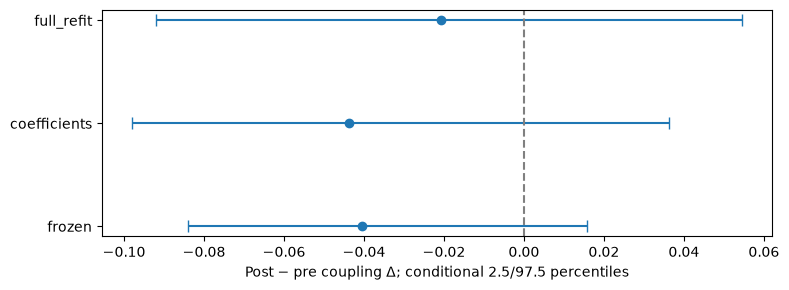

interactive(children=(Dropdown(description='protocol', index=1, options=('primary_block5', 'primary_block10', …

<function __main__.compare_refits(protocol='primary_block10', support='fixed')>

In [4]:
def compare_refits(protocol="primary_block10",support="fixed"):
    display(feasibility[feasibility.protocol==protocol])
    v=refit_summary[(refit_summary.protocol==protocol)&(refit_summary.support==support)]
    if v.empty:
        display(Markdown("**Range withheld:** fewer than 100 paired eligible draws. Inspect fit QC and the historical frozen branch in notebook 10."));return
    display(v[["mode","FC_draws","median","q025","q975","positive_fraction","SC_share","FC_share","interaction_share"]])
    shifts=pd.read_csv(REFIT/"paired_shifts.csv")
    display(shifts[(shifts.protocol==protocol)&(shifts.support==support)])
    fig,ax=plt.subplots(figsize=(8,3));y=np.arange(len(v))
    ax.errorbar(v["median"],y,xerr=np.vstack([v["median"]-v.q025,v.q975-v["median"]]),fmt="o",capsize=4)
    ax.axvline(0,color="gray",ls="--");ax.set_yticks(y,v["mode"]);ax.set_xlabel("Post − pre coupling Δ; conditional 2.5/97.5 percentiles")
    plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(compare_refits,protocol=widgets.Dropdown(options=list(RP),value="primary_block10"),support=widgets.Dropdown(options=["fixed","reselected"]))

## Inspect the actual draw and the two refitting steps
For a paired cell, Δ(full)−Δ(frozen) equals the sum of the coefficient-only shift and the further PC-training shift. This is ordered computational accounting, not independent causal sources. Subspace cosine² compares retained PC spans after multiplicity weighting; arbitrary PC signs are irrelevant. The full-refit estimator can change both the center and width of a range. Refitting need not simply widen a frozen range.

In [5]:
refit_fc=np.load(REFIT/"fc_draws.npy",mmap_mode="r")
def inspect_refit(protocol="primary_block10",draw=0):
    display(fit_qc[(fit_qc.protocol==protocol)&(fit_qc.draw==draw)])
    p=list(RP).index(protocol);v=refit_fc[p,:,:,draw]
    if not np.isfinite(v).all():
        print("This pair fails feasibility; unavailable FC is saved as NaN, not zero.");return
    from scipy.stats import spearmanr
    weights=np.load(RESULTS/"joint_sampling/sc_weights.npy",mmap_mode="r")[:,0]
    ii,jj=np.triu_indices(100,1);mask=np.load(RESULTS/"primary_sc/preop/common_support.npy")[ii,jj]
    r=np.array([[spearmanr(weights[t,mask],v[m,t,mask]).statistic for t in range(2)] for m in range(3)])
    display(pd.DataFrame({"mode":list(RM),"preop":r[:,0],"postop":r[:,1],"delta":r[:,1]-r[:,0]}))
widgets.interact(inspect_refit,protocol=widgets.Dropdown(options=list(RP),value="primary_block10"),draw=widgets.IntSlider(min=0,max=199,value=0))
display(pd.read_csv(REFIT/"monte_carlo_halves.csv"))

,protocol,mode,session,draw,mean_fd,minimum_PC_subspace_cos2,sample_rows,unique_frames,design_rank,solver_rank,rows_minus_rank,distinct_rows_minus_rank,eligible,reason,design_condition,tissue_voxels,PC_variance_fraction_sum,minimum_ROI_residual_SD
800,primary_block10,coefficients,preop,0,0.294622,1.000000,146,104,39,39,107,65,True,eligible,707.798617,NaN,NaN,0.695959
801,primary_block10,full_refit,preop,0,0.294622,0.053786,146,104,39,39,107,65,True,eligible,738.428253,11476.0,0.176874,0.759318
1200,primary_block10,coefficients,postop,0,0.264521,1.000000,150,99,39,39,111,60,True,eligible,976.922898,NaN,NaN,0.693777
1201,primary_block10,full_refit,postop,0,0.264521,0.628168,150,99,39,39,111,60,True,eligible,1028.722946,11324.0,0.197972,0.711570


,mode,preop,postop,delta
0,frozen,0.203179,0.126469,-0.076710
1,coefficients,0.188948,0.131761,-0.057187
2,full_refit,0.171103,0.117842,-0.053261


interactive(children=(Dropdown(description='protocol', index=1, options=('primary_block5', 'primary_block10', …

,protocol,support,mode,FC_draws,SC_draws,half,q025,median,q975,sd,positive_fraction
0,primary_block5,fixed,frozen,200,500,SC_first,-0.079123,-0.041939,0.009680,0.021795,0.04500
1,primary_block5,fixed,frozen,200,500,SC_second,-0.079253,-0.042025,0.009427,0.021801,0.04480
2,primary_block5,fixed,frozen,200,500,FC_first,-0.078734,-0.042180,0.015371,0.023259,0.05288
3,primary_block5,fixed,frozen,200,500,FC_second,-0.079589,-0.041859,0.005274,0.020144,0.03692
4,primary_block5,fixed,coefficients,200,500,SC_first,-0.095147,-0.037816,0.020835,0.030302,0.08360
...,...,...,...,...,...,...,...,...,...,...,...
67,primary_block20,reselected,coefficients,200,500,FC_second,-0.100580,-0.039775,0.022007,0.032166,0.10966
68,primary_block20,reselected,full_refit,200,500,SC_first,-0.096161,-0.030460,0.046281,0.036717,0.22458
69,primary_block20,reselected,full_refit,200,500,SC_second,-0.097310,-0.031200,0.046056,0.036993,0.21976
70,primary_block20,reselected,full_refit,200,500,FC_first,-0.098349,-0.031801,0.038593,0.035262,0.20130


## Reproduce and extend
Run `uv run python scripts/investigate_joint_refit.py`. `results/joint_refit/design.json` fingerprints code, configuration, saved draws and outputs. Exact repeated-row PCA/WLS equivalence, unchanged full-run point FC, frozen replay, rank/range identities and preservation of the preceding delivery are tested.

**Exercises:** compare block sizes 5/10/20; separate coefficient refitting from PC retraining; explain why an interval can shift without widening; inspect a failed strict pre-op draw; distinguish numerical rank from independent BOLD information; compare these full-run results with the 68-distinct-frame matched controls. Notebook 12 connects this evidence to the assessments without fitting two-point clinical associations. Notebook [13](13_pc_sampling_mechanisms.ipynb) separates tissue preprocessing from PCA-loading refits and shows that repeated-frame weights drive much of the recentering; it compares block subsampling without replacement. Empirical distribution shifts do not identify population bias.